# Udacity Data Engineer - Capstone Project


#### Project Summary
The objective of this project was to create an ETL pipeline for i94 immigration, US city demographics, global land temperatures and US Airport datasets to form an analytical database related to immigration patterns. This database can then be used to look for different trends in immigration such as city temperature and its impact on immigrants, popular arrival airports for immigrants, or immigration to cities with diverse population.

The project follows the follow steps:
* Step 1: Scope the Project and Gather Data
* Step 2: Explore and Assess the Data
* Step 3: Define the Data Model
* Step 4: Run ETL to Model the Data
* Step 5: Complete Project Write Up

In [11]:
# Do all imports and installs here
import pandas as pd
import time
import os
import configparser
from pyspark.sql.types import DateType,StringType
from pyspark.sql.functions import isnan, count, when, col,lit,udf,array
from pyspark.sql.functions import year, month, dayofmonth, hour, weekofyear, dayofweek, date_format, monotonically_increasing_id, to_date
from pyspark.sql import SparkSession, DataFrame
from datetime import datetime,timedelta
import boto3
from botocore.client import ClientError

In [12]:
#import config file
config = configparser.ConfigParser()
config.read('dl.cfg')

os.environ['AWS_ACCESS_KEY_ID']=config['AWS']['AWS_ACCESS_KEY_ID']
os.environ['AWS_SECRET_ACCESS_KEY']=config['AWS']['AWS_SECRET_ACCESS_KEY']

local_output_data = config['LOCAL']['LOCAL_OUTPUT']

s3_bucket_name = config['S3']['BUCKET_NAME']
s3_output_data = config['S3']['DEST_S3_BUCKET']

In [13]:
#Create Spark Session
spark = SparkSession.builder.\
config("spark.jars.repositories", "https://repos.spark-packages.org/").\
config("spark.jars.packages", "saurfang:spark-sas7bdat:2.0.0-s_2.11,org.apache.hadoop:hadoop-aws:2.7.0").\
enableHiveSupport().getOrCreate()


### Step 1: Scope the Project and Gather Data

#### Scope 

The goal of this project is to pull the data from the four datasets listed below and create a set of fact and dimension tables for analysis of it.

#### Describe and Gather Data 

Datasets:
1. **I94 Immigration Data** : This data comes from the US National Tourism and Trade Office. A data dictionary is included in the workspace. [This](https://travel.trade.gov/research/reports/i94/historical/2016.html) is where the data comes from. There's a sample file so you can take a look at the data in csv format before reading it all in. You do not have to use the entire dataset, just use what you need to accomplish the goal you set at the beginning of the project.
2. **World Temperature Data** : This dataset came from Kaggle. You can read more about it [here](https://www.kaggle.com/berkeleyearth/climate-change-earth-surface-temperature-data).
3. **U.S. City Demographic Data** : This data comes from OpenSoft. You can read more about it [here](https://public.opendatasoft.com/explore/dataset/us-cities-demographics/export/).
4. **Airport Code Table** : This is a simple table of airport codes and corresponding cities. It comes from [here](https://datahub.io/core/airport-codes#data).

Tools:
    
    AWS S3 for data storage
    Python for data processes
        - Pandas for analysis and processesing
        - Spark for processing
    
    

In [14]:
# Read I94 immigration data
# For this project, we will only read i94_apr16_sub.sas7bdat

fname = '../../data/18-83510-I94-Data-2016/i94_apr16_sub.sas7bdat'
## to import the file in pandas
df = pd.read_sas(fname, 'sas7bdat', encoding="ISO-8859-1")

## to import the file in spark
df_spark = spark.read.format('com.github.saurfang.sas.spark').load(fname)

df.head()

,cicid,i94yr,i94mon,i94cit,i94res,i94port,arrdate,i94mode,i94addr,depdate,...,entdepu,matflag,biryear,dtaddto,gender,insnum,airline,admnum,fltno,visatype
0,6.0,2016.0,4.0,692.0,692.0,XXX,20573.0,NaN,NaN,NaN,...,U,NaN,1979.0,10282016,NaN,NaN,NaN,1.897628e+09,NaN,B2
1,7.0,2016.0,4.0,254.0,276.0,ATL,20551.0,1.0,AL,NaN,...,Y,NaN,1991.0,D/S,M,NaN,NaN,3.736796e+09,00296,F1
2,15.0,2016.0,4.0,101.0,101.0,WAS,20545.0,1.0,MI,20691.0,...,NaN,M,1961.0,09302016,M,NaN,OS,6.666432e+08,93,B2
3,16.0,2016.0,4.0,101.0,101.0,NYC,20545.0,1.0,MA,20567.0,...,NaN,M,1988.0,09302016,NaN,NaN,AA,9.246846e+10,00199,B2
4,17.0,2016.0,4.0,101.0,101.0,NYC,20545.0,1.0,MA,20567.0,...,NaN,M,2012.0,09302016,NaN,NaN,AA,9.246846e+10,00199,B2


In [15]:
# Read country, state and port data from I94_SAS_Labels_Descriptions.SAS
#dim_country data is in lines 10-298
#dim_port is in lines 303-962
#dim_state is in lines 982-1036

with open("I94_SAS_Labels_Descriptions.SAS") as f:
    desc = f.readlines()


In [16]:
# Read world temperature data
fname = '../../data2/GlobalLandTemperaturesByCity.csv'
temp_spark_df = spark.read.csv(fname,header=True,inferSchema=True)
temp_panda_df = pd.read_csv(fname)

temp_panda_df.head()

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1743-11-01,6.068,1.737,Århus,Denmark,57.05N,10.33E
1,1743-12-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
2,1744-01-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
3,1744-02-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
4,1744-03-01,NaN,NaN,Århus,Denmark,57.05N,10.33E


In [17]:
# Read US City demographics data
fname = "us-cities-demographics.csv"
demo_spark_df = spark.read.csv(fname,header=True,inferSchema=True,sep=';')
demo_panda_df = pd.read_csv(fname,sep=';')

demo_panda_df.head()

,City,State,Median Age,Male Population,Female Population,Total Population,Number of Veterans,Foreign-born,Average Household Size,State Code,Race,Count
0,Silver Spring,Maryland,33.8,40601.0,41862.0,82463,1562.0,30908.0,2.60,MD,Hispanic or Latino,25924
1,Quincy,Massachusetts,41.0,44129.0,49500.0,93629,4147.0,32935.0,2.39,MA,White,58723
2,Hoover,Alabama,38.5,38040.0,46799.0,84839,4819.0,8229.0,2.58,AL,Asian,4759
3,Rancho Cucamonga,California,34.5,88127.0,87105.0,175232,5821.0,33878.0,3.18,CA,Black or African-American,24437
4,Newark,New Jersey,34.6,138040.0,143873.0,281913,5829.0,86253.0,2.73,NJ,White,76402


In [18]:
# Read Airport Data
fname="airport-codes_csv.csv"
airport_spark_df = spark.read.csv(fname,header=True,inferSchema=True,sep=',')
airport_panda_df = pd.read_csv(fname,sep=',')

airport_panda_df.head()

,ident,type,name,elevation_ft,continent,iso_country,iso_region,municipality,gps_code,iata_code,local_code,coordinates
0,00A,heliport,Total Rf Heliport,11.0,NaN,US,US-PA,Bensalem,00A,NaN,00A,"-74.93360137939453, 40.07080078125"
1,00AA,small_airport,Aero B Ranch Airport,3435.0,NaN,US,US-KS,Leoti,00AA,NaN,00AA,"-101.473911, 38.704022"
2,00AK,small_airport,Lowell Field,450.0,NaN,US,US-AK,Anchor Point,00AK,NaN,00AK,"-151.695999146, 59.94919968"
3,00AL,small_airport,Epps Airpark,820.0,NaN,US,US-AL,Harvest,00AL,NaN,00AL,"-86.77030181884766, 34.86479949951172"
4,00AR,closed,Newport Hospital & Clinic Heliport,237.0,NaN,US,US-AR,Newport,NaN,NaN,NaN,"-91.254898, 35.6087"


### Step 2: Explore and Assess the Data

Explore each dataset and clean the data as necessary

##### Immigration dataset

In [19]:
#Create country, state, and port reference tables from I94_SAS_Labels_Descriptions.SAS

country_dict = {}
for countries in desc[10:298]:
    data=countries.split("=")
    country_code,country_name = data[0].strip(),data[1].strip().strip("'")
    country_dict[country_code]=country_name
country_df = pd.DataFrame(list(country_dict.items()),columns=['country_code','country_name'])
    
port_dict = {}
for ports in desc[303:962]:
    data=ports.split("=")
    port_code,port_name = data[0].strip().strip("'"),data[1].strip("\t").strip().strip("'").strip()
    port_dict[port_code]=port_name
    
port_df = pd.DataFrame(list(port_dict.items()),columns=['port_code','port_name'])

state_dict = {}
for states in desc[982:1036]:
    data=states.split("=")
    state_code,state_name = data[0].strip("\t").strip("'"),data[1].strip().strip("'")
    state_dict[state_code]=state_name
    
state_df = pd.DataFrame(list(state_dict.items()),columns=['state_code','state_name'])


In [20]:
country_df.head()

,country_code,country_name
0,236,AFGHANISTAN
1,101,ALBANIA
2,316,ALGERIA
3,102,ANDORRA
4,324,ANGOLA


In [21]:
state_df.head()

,state_code,state_name
0,AK,ALASKA
1,AZ,ARIZONA
2,AR,ARKANSAS
3,CA,CALIFORNIA
4,CO,COLORADO


In [22]:
port_df.head()

,port_code,port_name
0,ANC,"ANCHORAGE, AK"
1,BAR,"BAKER AAF - BAKER ISLAND, AK"
2,DAC,"DALTONS CACHE, AK"
3,PIZ,"DEW STATION PT LAY DEW, AK"
4,DTH,"DUTCH HARBOR, AK"


In [23]:
#Clean i94 immigration data
#From EDA we know 3 columns that have more that 90% missing data so we will drop them
columns_with_high_missing = ['occup', 'entdepu', 'insnum']
df_spark = df_spark.drop(*columns_with_high_missing)

In [24]:
# There are three types of visa codes which we will replace with the description
    #   1 = Business
    #   2 = Pleasure
    #   3 = Student

df_spark = df_spark.withColumn('i94visa',
                               when(df_spark['i94visa'] == '1', 'Business')
                               .when(df_spark['i94visa'] == '2', 'Pleasure')
                               .when(df_spark['i94visa'] == '3', 'Student')
                               .otherwise('Unknown') )

In [25]:
#Create UDF to convert SAS date to datetime for arrdate column
@udf(DateType())
def convert_sas_date(sas_date):
    if sas_date is not None:
        epoch_start = datetime(1960, 1, 1)
        return (epoch_start + timedelta(days=int(sas_date))).date()


In [26]:
df_spark = df_spark.withColumn('arrival_date', convert_sas_date(col('arrdate')))


In [27]:
#Clean up state column "i94addr"
#Create udf function to clean up the states values
@udf(StringType())
def validate_state_code(x):
    if x in valid_states:
        return x
    return "99"

In [28]:
valid_states = state_df["state_code"].unique()

In [29]:
#clean up state column "i94addr" in fact_immi
clean_df_spark = df_spark.withColumn("i94addr",validate_state_code(df_spark.i94addr))

In [30]:
clean_df_spark.head(5)

[Row(cicid=6.0, i94yr=2016.0, i94mon=4.0, i94cit=692.0, i94res=692.0, i94port='XXX', arrdate=20573.0, i94mode=None, i94addr='99', depdate=None, i94bir=37.0, i94visa='Pleasure', count=1.0, dtadfile=None, visapost=None, entdepa='T', entdepd=None, matflag=None, biryear=1979.0, dtaddto='10282016', gender=None, airline=None, admnum=1897628485.0, fltno=None, visatype='B2', arrival_date=datetime.date(2016, 4, 29)),
 Row(cicid=7.0, i94yr=2016.0, i94mon=4.0, i94cit=254.0, i94res=276.0, i94port='ATL', arrdate=20551.0, i94mode=1.0, i94addr='99', depdate=None, i94bir=25.0, i94visa='Student', count=1.0, dtadfile='20130811', visapost='SEO', entdepa='G', entdepd=None, matflag=None, biryear=1991.0, dtaddto='D/S', gender='M', airline=None, admnum=3736796330.0, fltno='00296', visatype='F1', arrival_date=datetime.date(2016, 4, 7)),
 Row(cicid=15.0, i94yr=2016.0, i94mon=4.0, i94cit=101.0, i94res=101.0, i94port='WAS', arrdate=20545.0, i94mode=1.0, i94addr='MI', depdate=20691.0, i94bir=55.0, i94visa='Pleasu

##### Temperature Dataset

In [31]:
print(temp_spark_df.count()) #spark df
print(temp_panda_df.shape) #panda df

8599212
(8599212, 7)


In [32]:
temp_spark_df.printSchema()

root
 |-- dt: timestamp (nullable = true)
 |-- AverageTemperature: double (nullable = true)
 |-- AverageTemperatureUncertainty: double (nullable = true)
 |-- City: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Longitude: string (nullable = true)



In [33]:
temp_panda_df.head()

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1743-11-01,6.068,1.737,Århus,Denmark,57.05N,10.33E
1,1743-12-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
2,1744-01-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
3,1744-02-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
4,1744-03-01,NaN,NaN,Århus,Denmark,57.05N,10.33E


In [34]:
#Drop rows where 'AverageTemperature' data is missing
temp_spark_df = temp_spark_df.dropna(subset=['AverageTemperature'])

In [35]:
#Drop rows for duplicate data for dt,city,country
temp_spark_df = temp_spark_df.drop_duplicates(subset=['dt','City','Country'])

In [36]:
#Exclude data prior to 1960-1-1. (assumption is we don't have travel records prior to that)
temp_spark_df = temp_spark_df.filter(to_date(col('dt')) >= to_date(lit('1960-01-01')))

In [37]:
temp_spark_df.count()

2247991

In [38]:
temp_spark_df.limit(5).toPandas()

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1960-01-01,24.592,0.317,Benguela,Angola,12.05S,13.15E
1,1960-01-01,19.149,0.590,Bhusawal,India,21.70N,75.29E
2,1960-01-01,23.405,0.541,Blumenau,Brazil,26.52S,48.36W
3,1960-01-01,27.865,0.362,Bohicon,Benin,7.23N,2.43E
4,1960-01-01,18.735,0.431,Chhindwara,India,21.70N,78.75E


##### US City Demographics

In [39]:
print(demo_spark_df.count()) #spark df
print(demo_panda_df.shape) #panda df
demo_spark_df.printSchema()

2891
(2891, 12)
root
 |-- City: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Median Age: double (nullable = true)
 |-- Male Population: integer (nullable = true)
 |-- Female Population: integer (nullable = true)
 |-- Total Population: integer (nullable = true)
 |-- Number of Veterans: integer (nullable = true)
 |-- Foreign-born: integer (nullable = true)
 |-- Average Household Size: double (nullable = true)
 |-- State Code: string (nullable = true)
 |-- Race: string (nullable = true)
 |-- Count: integer (nullable = true)



In [40]:
demo_panda_df.head()

,City,State,Median Age,Male Population,Female Population,Total Population,Number of Veterans,Foreign-born,Average Household Size,State Code,Race,Count
0,Silver Spring,Maryland,33.8,40601.0,41862.0,82463,1562.0,30908.0,2.60,MD,Hispanic or Latino,25924
1,Quincy,Massachusetts,41.0,44129.0,49500.0,93629,4147.0,32935.0,2.39,MA,White,58723
2,Hoover,Alabama,38.5,38040.0,46799.0,84839,4819.0,8229.0,2.58,AL,Asian,4759
3,Rancho Cucamonga,California,34.5,88127.0,87105.0,175232,5821.0,33878.0,3.18,CA,Black or African-American,24437
4,Newark,New Jersey,34.6,138040.0,143873.0,281913,5829.0,86253.0,2.73,NJ,White,76402


In [41]:
#EDA has show the below columns has some null data so we will drop those rows
demo_spark_df = demo_spark_df.dropna(subset=[
        'Male Population',
        'Female Population',
        'Number of Veterans',
        'Foreign-born',
        'Average Household Size'
    ])

In [42]:
demo_spark_df.limit(5).toPandas()

,City,State,Median Age,Male Population,Female Population,Total Population,Number of Veterans,Foreign-born,Average Household Size,State Code,Race,Count
0,Silver Spring,Maryland,33.8,40601,41862,82463,1562,30908,2.60,MD,Hispanic or Latino,25924
1,Quincy,Massachusetts,41.0,44129,49500,93629,4147,32935,2.39,MA,White,58723
2,Hoover,Alabama,38.5,38040,46799,84839,4819,8229,2.58,AL,Asian,4759
3,Rancho Cucamonga,California,34.5,88127,87105,175232,5821,33878,3.18,CA,Black or African-American,24437
4,Newark,New Jersey,34.6,138040,143873,281913,5829,86253,2.73,NJ,White,76402


##### Airport Data

In [43]:
print(airport_spark_df.count())
print(airport_panda_df.shape)
airport_spark_df.printSchema()

55075
(55075, 12)
root
 |-- ident: string (nullable = true)
 |-- type: string (nullable = true)
 |-- name: string (nullable = true)
 |-- elevation_ft: integer (nullable = true)
 |-- continent: string (nullable = true)
 |-- iso_country: string (nullable = true)
 |-- iso_region: string (nullable = true)
 |-- municipality: string (nullable = true)
 |-- gps_code: string (nullable = true)
 |-- iata_code: string (nullable = true)
 |-- local_code: string (nullable = true)
 |-- coordinates: string (nullable = true)



In [44]:
airport_panda_df.head()

,ident,type,name,elevation_ft,continent,iso_country,iso_region,municipality,gps_code,iata_code,local_code,coordinates
0,00A,heliport,Total Rf Heliport,11.0,NaN,US,US-PA,Bensalem,00A,NaN,00A,"-74.93360137939453, 40.07080078125"
1,00AA,small_airport,Aero B Ranch Airport,3435.0,NaN,US,US-KS,Leoti,00AA,NaN,00AA,"-101.473911, 38.704022"
2,00AK,small_airport,Lowell Field,450.0,NaN,US,US-AK,Anchor Point,00AK,NaN,00AK,"-151.695999146, 59.94919968"
3,00AL,small_airport,Epps Airpark,820.0,NaN,US,US-AL,Harvest,00AL,NaN,00AL,"-86.77030181884766, 34.86479949951172"
4,00AR,closed,Newport Hospital & Clinic Heliport,237.0,NaN,US,US-AR,Newport,NaN,NaN,NaN,"-91.254898, 35.6087"


In [45]:
# EDA has shown we only need data for US airports and ignore any
# rows that have null municipality

airport_spark_df = airport_spark_df.filter(airport_spark_df['iso_country'] =='US')
airport_spark_df = airport_spark_df.dropna(subset=['municipality'])

In [46]:
print(airport_spark_df.count())

22655


In [47]:
airport_spark_df.limit(5).toPandas()

,ident,type,name,elevation_ft,continent,iso_country,iso_region,municipality,gps_code,iata_code,local_code,coordinates
0,00A,heliport,Total Rf Heliport,11,NA,US,US-PA,Bensalem,00A,None,00A,"-74.93360137939453, 40.07080078125"
1,00AA,small_airport,Aero B Ranch Airport,3435,NA,US,US-KS,Leoti,00AA,None,00AA,"-101.473911, 38.704022"
2,00AK,small_airport,Lowell Field,450,NA,US,US-AK,Anchor Point,00AK,None,00AK,"-151.695999146, 59.94919968"
3,00AL,small_airport,Epps Airpark,820,NA,US,US-AL,Harvest,00AL,None,00AL,"-86.77030181884766, 34.86479949951172"
4,00AR,closed,Newport Hospital & Clinic Heliport,237,NA,US,US-AR,Newport,None,None,None,"-91.254898, 35.6087"


### Step 3: Define the Data Model
#### 3.1 Conceptual Data Model
Map out the conceptual data model and explain why you chose that model


Star schema was chosed as the data model as it is simple and effective in terms of query performance. The data could be denormalized down to fact and dimension tables allowing for easy joins and effiecient query performance.

Here are the fact and dimension tables for the schema:

   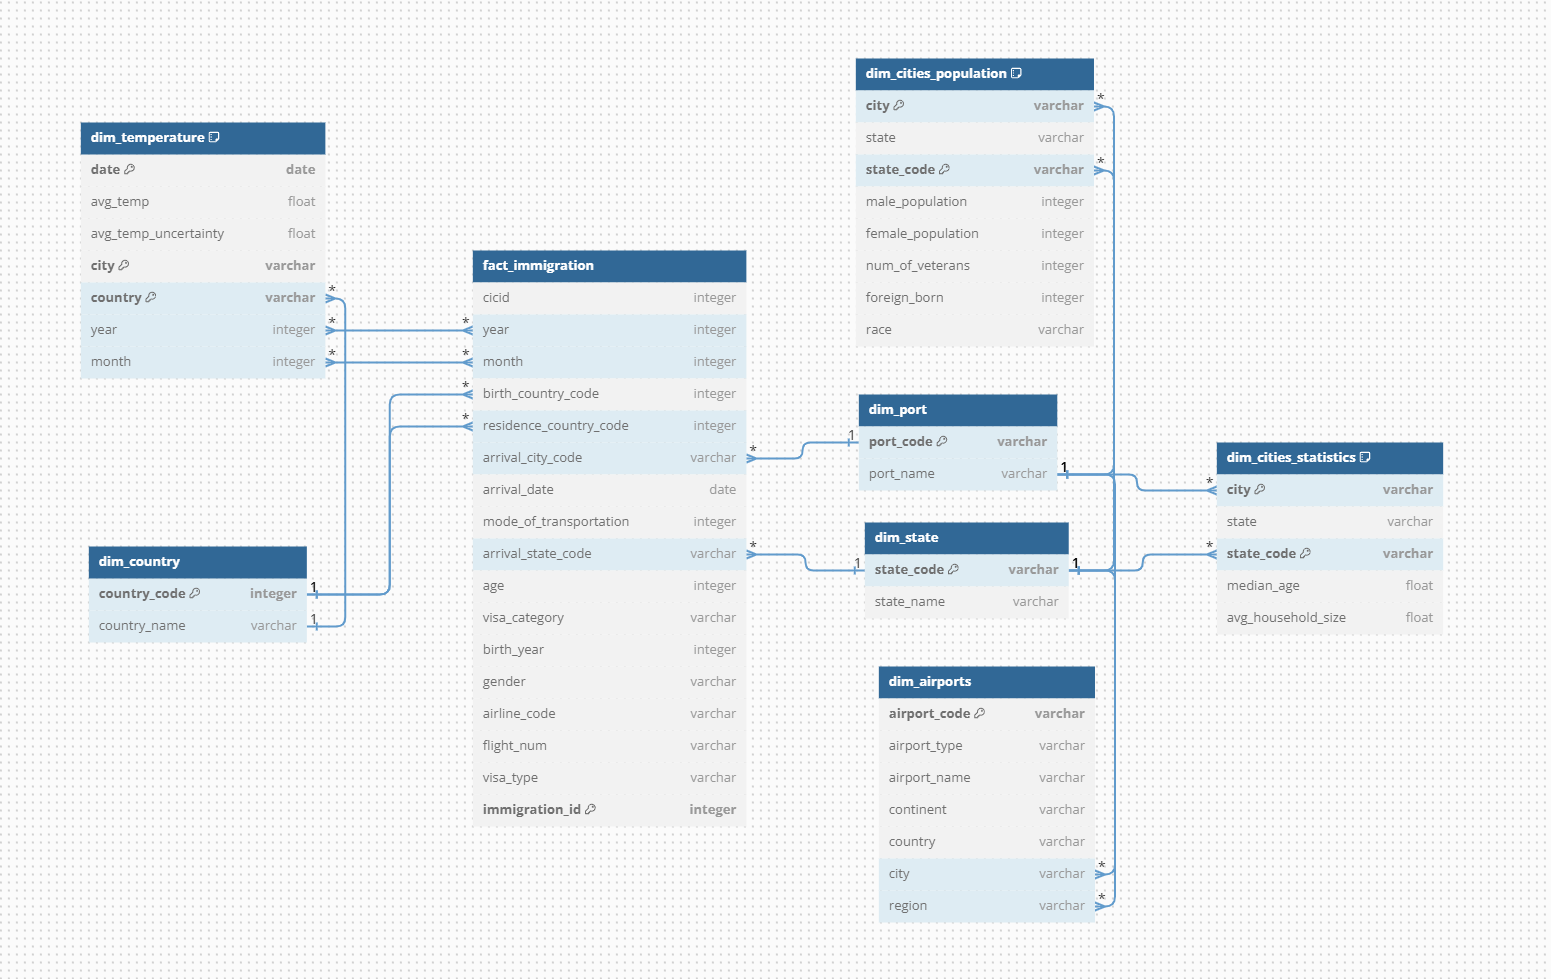

#### 3.2 Mapping Out Data Pipelines
List the steps necessary to pipeline the data into the chosen data model

    1. Load all data files into spark dataframe
    2. Drop empty columns,clear null and duplicate rows and remove unneccesary rows
    3. Convert date columns from SAS format to datetime
    4. Convert state columns in i94 data for invalid values
    5. Create fact table fact_immigration from i94 immigration data
    6. Create dimension tables from global temperature, US demographics, i94 sas description and airport datasets.
    7. Save the fact and dimensions tables in parquet format on S3 for downstream streams

### Step 4: Run Pipelines to Model the Data 
#### 4.1 Create the data model
Build the data pipelines to create the data model.

We cleaned all the data in spark dataframes in Step 3. Now we save them to fact and dimension tables and write to S3 in parquet format.


**Note:** `etl.py` was created as well to automate the entire data pipeline.

In [48]:
#create immigration fact table fact_immigration
fact_immigration = clean_df_spark.select('cicid','i94yr','i94mon','i94cit',\
                    'i94res','i94port','arrival_date','i94mode','i94addr',\
                    'i94bir','i94visa','biryear','gender','airline',\
                    'fltno','visatype')\
                    .withColumnRenamed('i94yr','year') \
                    .withColumnRenamed('i94mon','month') \
                    .withColumnRenamed('i94cit','birth_country_code') \
                    .withColumnRenamed('i94res','residence_country_code') \
                    .withColumnRenamed('i94port','arrival_city_code') \
                    .withColumnRenamed('arrdate','arrival_date') \
                    .withColumnRenamed('i94mode','mode_of_transportation') \
                    .withColumnRenamed('i94addr','arrival_state_code') \
                    .withColumnRenamed('i94bir','age') \
                    .withColumnRenamed('i94visa','visa_category') \
                    .withColumnRenamed('biryear','birth_year') \
                    .withColumnRenamed('airline','airline_code') \
                    .withColumnRenamed('fltno','flight_num') \
                    .withColumnRenamed('visatype','visa_type') \
                    .distinct()\
                    .withColumn('immigration_id',monotonically_increasing_id())

#convert country,port and state panda df to spark df to write the dimension table as parquet files
#dim tables will be dim_country, dim_port, and dim_state

dim_country = spark.createDataFrame(country_df) 
dim_port = spark.createDataFrame(port_df)
dim_state = spark.createDataFrame(state_df)


fact_immigration.limit(5)

DataFrame[cicid: double, year: double, month: double, birth_country_code: double, residence_country_code: double, arrival_city_code: string, arrival_date: date, mode_of_transportation: double, arrival_state_code: string, age: double, visa_category: string, birth_year: double, gender: string, airline_code: string, flight_num: string, visa_type: string, immigration_id: bigint]

In [49]:
#Create temperature dim table dim_temperature
dim_temperature = temp_spark_df.select('dt','AverageTemperature', \
                                           'AverageTemperatureUncertainty', \
                                           'City','Country' ) \
                                    .withColumnRenamed('dt','date') \
                                    .withColumnRenamed('AverageTemperature','avg_temp') \
                                    .withColumnRenamed('AverageTemperatureUncertainty','avg_temp_uncertainty') \
                                    .withColumnRenamed('City','city') \
                                    .withColumnRenamed('Country','country')

dim_temperature = dim_temperature.withColumn('date',to_date(col('date')))
dim_temperature = dim_temperature.withColumn('year',year(dim_temperature['date']))
dim_temperature = dim_temperature.withColumn('month',month(dim_temperature['date']))

dim_temperature.limit(5).toPandas()

,date,avg_temp,avg_temp_uncertainty,city,country,year,month
0,1964-03-01,28.818,0.188,Abakaliki,Nigeria,1964,3
1,1961-06-01,25.496,0.390,Abidjan,Côte D'Ivoire,1961,6
2,1960-02-01,26.279,0.508,Angeles,Philippines,1960,2
3,1960-05-01,26.383,0.498,Araguaína,Brazil,1960,5
4,1960-06-01,26.470,0.367,Anaco,Venezuela,1960,6


In [50]:
#Create a city-population dimension table dim_cities_population
dim_cities_population = demo_spark_df.select('City','State','State Code','Male Population', \
                                                 'Female Population', \
                                                 'Number of Veterans','Foreign-born','Race') \
                                         .withColumnRenamed('City','city') \
                                         .withColumnRenamed('State','state') \
                                         .withColumnRenamed('State Code','state_code') \
                                         .withColumnRenamed('Male Population','male_population') \
                                         .withColumnRenamed('Female Population','female_population') \
                                         .withColumnRenamed('Number of Veterans','num_of_veterans') \
                                         .withColumnRenamed('Foreign-born','foreign_born') \
                                         .withColumnRenamed('Race','race')

dim_cities_population.limit(5).toPandas()

,city,state,state_code,male_population,female_population,num_of_veterans,foreign_born,race
0,Silver Spring,Maryland,MD,40601,41862,1562,30908,Hispanic or Latino
1,Quincy,Massachusetts,MA,44129,49500,4147,32935,White
2,Hoover,Alabama,AL,38040,46799,4819,8229,Asian
3,Rancho Cucamonga,California,CA,88127,87105,5821,33878,Black or African-American
4,Newark,New Jersey,NJ,138040,143873,5829,86253,White


In [51]:
#Create a city-statistics dimension table
dim_cities_statistics = demo_spark_df.select('City','State','State Code','Median Age', \
                                                 'Average Household Size') \
                                         .withColumnRenamed('City','city') \
                                         .withColumnRenamed('State','state') \
                                         .withColumnRenamed('State Code','state_code') \
                                         .withColumnRenamed('Median Age','median_age') \
                                         .withColumnRenamed('Average Household Size','avg_household_size')

dim_cities_statistics.limit(5).toPandas()

,city,state,state_code,median_age,avg_household_size
0,Silver Spring,Maryland,MD,33.8,2.60
1,Quincy,Massachusetts,MA,41.0,2.39
2,Hoover,Alabama,AL,38.5,2.58
3,Rancho Cucamonga,California,CA,34.5,3.18
4,Newark,New Jersey,NJ,34.6,2.73


In [52]:
#Create airport dimension table dim_airports
dim_airports = airport_spark_df.select('ident','type','name', \
                                       'continent','iso_country','iso_region','municipality') \
                                .withColumnRenamed('ident','airport_code') \
                                .withColumnRenamed('type','airport_type') \
                                .withColumnRenamed('name','airport_name') \
                                .withColumnRenamed('continent','continent') \
                                .withColumnRenamed('iso_country','country') \
                                .withColumnRenamed('iso_region','region') \
                                .withColumnRenamed('municipality','city')

dim_airports.limit(5).toPandas()

,airport_code,airport_type,airport_name,continent,country,region,city
0,00A,heliport,Total Rf Heliport,NA,US,US-PA,Bensalem
1,00AA,small_airport,Aero B Ranch Airport,NA,US,US-KS,Leoti
2,00AK,small_airport,Lowell Field,NA,US,US-AK,Anchor Point
3,00AL,small_airport,Epps Airpark,NA,US,US-AL,Harvest
4,00AR,closed,Newport Hospital & Clinic Heliport,NA,US,US-AR,Newport


In [53]:
#Write the dimension tables to parquet format locally first and then upload to S3

dim_country.write.mode("overwrite").parquet(path=local_output_data + 'dim_country')
dim_port.write.mode("overwrite").parquet(path=local_output_data + 'dim_port')
dim_state.write.mode("overwrite").parquet(path=local_output_data + 'dim_state')
dim_temperature.coalesce(20).write.mode("overwrite").partitionBy('country').parquet(path=local_output_data + 'dim_temperature')
dim_cities_population.write.mode("overwrite").parquet(path=local_output_data + 'dim_cities_population')
dim_cities_statistics.write.mode("overwrite").parquet(path=local_output_data + 'dim_cities_statistics')
dim_airports.write.mode("overwrite").parquet(path=local_output_data + 'dim_airports')

#Write the fact table to parquet format
fact_immigration.coalesce(20).write.mode("overwrite").partitionBy('arrival_state_code').parquet(path=local_output_data + 'fact_immigration')

In [54]:
def upload_to_S3(Path):
    """A loop occurs over all files in the path input to filter files and upload them to s3 bucket""" 
    success_count = 0
    failure_count = 0
    
    #empty the s3 bucket first before uploading
    s3 = boto3.resource('s3')
    bucket = s3.Bucket(s3_bucket_name)
    result=  bucket.objects.all().delete()
    
    for subdir, dirs, files in os.walk(Path):
        for filename in files:
            # # only transfer .parquet files
            file = os.path.join(subdir, filename)
            ext = os.path.splitext(file)[-1].lower()
            if ext == '.parquet':                
                full_file = os.path.join(subdir,filename)
                s3_data = os.path.join(subdir,filename)
                local_file_path = full_file
                s3_object = s3_data.replace(local_output_data,'')
                
                # Upload the file
                s3_client = boto3.client('s3')
                try:    
                    response = s3_client.upload_file(local_file_path, s3_bucket_name, s3_object)
                    success_count += 1
                except ClientError as e:
                    print(e)
                    failure_count +=1
    if failure_count == 0:
        print("All files uploaded successfully to S3!")
    else:
        print(f"{failure_count} files failed to upload.")

In [55]:
#Upload the data to S3
upload_to_S3(local_output_data)   

All files uploaded successfully to S3!


#### 4.2 Data Quality Checks

Validate all the tables were created on S3 and they are not empty.

In [56]:
#bucket_name = config['S3']['BUCKET_NAME']
#output_data = config['S3']['DEST_S3_BUCKET']


In [62]:
def checkBucket(file_path):
    """
    Checks the existense of the S3 bucket and directory

    Args:
        file_path (str): Directory in S3 bucket

    Returns:
        bool: True if bucket and directory exists
    """
    client = boto3.client('s3')
    result = client.list_objects(Bucket=s3_bucket_name, Prefix=file_path )
    if 'Contents' in result:
        return True
    else:
        return False


In [63]:
def validate_data_load(spark):

    #Expect all the fact and dim tables to exist and have data
    tbl_list=['fact_immigration/',
          'dim_country/',
          'dim_state/',
          'dim_port/',
          'dim_temperature/',
          'dim_cities_population/',
          'dim_cities_statistics/',
          'dim_airports/'
    ]
    #Check if fact and dimension tables exits and contains data on S3
    for tbl in tbl_list:
        print(f">>>>Validating table: {tbl}    ")
        if checkBucket(tbl):
            print(f"    PASSED! {tbl} directory exists. Checking count...")
            df = spark.read.parquet(s3_output_data + tbl)
            rec_count = df.count()
            if rec_count >0:
                print(f"    PASSED! {tbl} has {rec_count} records.")
            else:
                print(f"    FAILED! {tbl} is empty.")
        else:
            print(f"    FAILED! {tbl} directory does not exists")


In [64]:
#Perform quality checks here

#validate all the fact and dimension tables exists
validate_data_load(spark)

>>>>Validating table: fact_immigration/    
    PASSED! fact_immigration/ directory exists. Checking count...
    PASSED! fact_immigration/ has 3096313 records.
>>>>Validating table: dim_country/    
    PASSED! dim_country/ directory exists. Checking count...
    PASSED! dim_country/ has 288 records.
>>>>Validating table: dim_state/    
    PASSED! dim_state/ directory exists. Checking count...
    PASSED! dim_state/ has 54 records.
>>>>Validating table: dim_port/    
    PASSED! dim_port/ directory exists. Checking count...
    PASSED! dim_port/ has 659 records.
>>>>Validating table: dim_temperature/    
    PASSED! dim_temperature/ directory exists. Checking count...
    PASSED! dim_temperature/ has 2247991 records.
>>>>Validating table: dim_cities_population/    
    PASSED! dim_cities_population/ directory exists. Checking count...
    PASSED! dim_cities_population/ has 2875 records.
>>>>Validating table: dim_cities_statistics/    
    PASSED! dim_cities_statistics/ directory exis

#### 4.3 Data dictionary 



**fact_immigration**


| **Column_Name**         | **Column_Description**                                                |
|-------------------------|-----------------------------------------------------------------------|
| cicid                   |  Unique record id                                                     |
| year                    |  Year of arrival                                                      |
| month                   |  Month of arrival                                                     |
| birth_country_code      |  birth country code                                                   |
| residence_country_code  |  residence country code                                               |
| arrival_city_code       |  arrival city code                                                    |
| arrival_date            |  date of arrival                                                      |
| mode_of_transportation  |  mode of transportation. Ex. Air,   Sea, etc.                         |
| arrival_state_code      |  arrival state code                                                   |
| age                     |  Age                                                                  |
| visa_category           |  Visa types categorized in 3   categories:  Business,Student,Pleasure |
| birth_year              |  Year of birth                                                        |
| gender                  |  Immigrants Gender                                                    |
| airline_code            |  Airline code of the airline used   to arrive                         |
| flight_num              |  Airline flight number                                                |
| visa_type               |  Visa type used to enter U.S                                          |
| immigration_id          |  Unique primary key ID                                                |


**dim_country**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| country_code          |  Country Code                                     |
| country_name          |  Country Name                                     |



**dim_state**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| state_code            |  State Code                                       |
| state_name            |  State Name                                       |


**dim_port**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| port_code             |  Port Code                                        |
| port_name             |  Port Name                                        |


**dim_temperature**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| date                  |  Date                                             |
| avg_temp              |  global average land temperature   in celsius    |
| avg_temp_uncertainty  |  the 95% confidence interval around   the average |
| city                  |  Name of City                                     |
| country               |  Name of Country                                  |
| year                  |  Year derived from Date                           |
| month                 |  Month derived from Date                          |


**dim_cities_statistics**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| city                  |  Name of City                                     |
| state                 |  Name of State                                    |
| state_code            |  State Code                                       |
| median_age            |  Median Age of population                         |
| avg_household_size    |  Average city household size                      |


**dim_cities_population**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| city                  |  Name of City                                     |
| state                 |  Name of State                                    |
| state_code            |  State Code                                       |
| male_population       |  Count of Male population                         |
| female_population     |  Count of Female population                       |
| num_of_veterans       |  Count of Total Veterans                          |
| foreign_born          |  Count of residents born in a   different city    |
| race                  |  Respondent race                                  |


**dim_airports**

| **Column_Name**       | **Column_Description**                            |
|-----------------------|---------------------------------------------------|
| airport_code          |  Airport Code                                     |
| airport_type          |  Airport Type                                     |
| airport_name          |  Airport Name                                     |
| continent             |  Continent                                        |
| country               |  Country                                          |
| region                |  Region                                           |
| city                  |  City                                             |

#### Step 5: Complete Project Write Up

 
**Tools**:

The immigration data for the fact table consists of ~3M rows each month so Spark was the too of choice for loading and processing the data. Apache Spark is efficient when it comes to processing large amounts of data. AWS S3 was used for storage since its easily scalable if data volumne increases.


`AWS S3 for data storage`

`Python for data processing`
    - Pandas for analysis and processing
    - Spark for processing
    

**Frequency of Data Update**

Immigration data for the fact table is updated monthy so we can update all the data on a monthly cadence. An argument could also be made for a quaterly update since most of the analysis and reports would be looking at trends over a period of time which doesn't require a frequent update of the data.

**Alternate Scenario**

_The data was increased by 100x._
-  We can switch from a standalone Spark cluster to AWS EMR which can handle large datasets on cloud using distributed data clusters.
 
_The data populates a dashboard that must be updated on a daily basis by 7am every day._
-  Apache Airflow can be used to build and run the ETL data pipeline and pass the data to downstream systems for daily dashboard update.
 
_The database needed to be accessed by 100+ people._
-  The final data can be loaded into a Redshift database which can handle multi user access with ease.

